# The Output-Level Classification

Thesis: *Results*, section *The Output-Level Classification*.

The readouts come from `src/measurement/classify_depicted_gender.py`.

**Requirements**
- Environment: `easy-language` (`environment-easy-language.yml`)
- Packages: pandas, matplotlib, seaborn
- Data: `data/main_run/mivolo_results.csv`, `data/order_swap/mivolo_results.csv` (in this repository)
- GPU and network: not needed

**Writes:** `figures/depicted-gender.pdf`, `figures/low-context.pdf`, `exports/order_swap_comparison.csv`

In [1]:
import os
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "corpus").is_dir())
os.chdir(ROOT)

from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from matplotlib.lines import Line2D

from IPython.display import display

GSL_COLOUR, GAL_COLOUR = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#9c9b95"
STYLE = {"GSL": (GSL_COLOUR, "o"), "GAL": (GAL_COLOUR, "^")}
LANGUAGE_FORM = {"ls": "GAL", "sd": "GSL"}
PROFESSIONS = {  # in the order of the Misersky et al. (2014) norm
    "mechaniker": "Kfz-Mechaniker", "elektriker": "Elektriker", "baecker": "Bäcker",
    "fotograf": "Fotograf", "reinigungskraft": "Reinigungskraft", "florist": "Florist",
}

## Depicted gender per condition

The generic masculine yields almost only images read as male whatever the profession, while the neutral term follows the stereotype direction of the profession.

In [2]:
READOUT = Path("data/main_run/mivolo_results.csv")
OUT_PATH = Path("figures/depicted-gender.pdf")


FORM_LABELS = {
    "generic_masc": "generic masculine",
    "neutral_term": "neutral term",
    "pair_form": "pair form",
    "typographical": "typographical form",
}
ROW_OFFSET = 0.16


def load_shares() -> pd.DataFrame:
    """Share of single-person images read as male, per profession, gender form and language form."""
    df = pd.read_csv(READOUT)
    df = df[(df["set"] == "test") & (df["scene_label"] != "low_context")
            & (df["readout_status"] == "single")
            & (df["face_available"].astype(str) == "True")].copy()
    df["language_form"] = df["variety"].map(LANGUAGE_FORM)
    df["male"] = df["gender"] == "male"
    shares = (df.groupby(["profession", "condition", "language_form"])["male"]
              .agg(share="mean", n="size").reset_index())
    shares["share"] *= 100
    return shares


def plot(shares: pd.DataFrame, stacked: bool = False, out_path: Path = OUT_PATH) -> None:
    sns.set_theme(style="whitegrid")
    plt.rcParams.update({
        "font.size": 8, "axes.titlesize": 8.5, "axes.labelsize": 8.5,
        "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    })
    shape = (4, 1) if stacked else (1, 4)
    size = (5.8, 6.2) if stacked else (5.8, 2.5)
    fig, axes = plt.subplots(*shape, figsize=size, sharex=True, sharey=True, layout="constrained")
    rows = {key: i for i, key in enumerate(reversed(list(PROFESSIONS)))}

    for ax, (condition, title) in zip(axes, FORM_LABELS.items()):
        cell = shares[shares["condition"] == condition]
        for language_form, (colour, marker) in STYLE.items():
            sub = cell[cell["language_form"] == language_form]
            sign = -1 if language_form == "GSL" else 1
            ax.plot(sub["share"], [rows[p] + sign * ROW_OFFSET for p in sub["profession"]],
                    marker, color=colour, markersize=5, linestyle="none",
                    label=language_form, zorder=3)
        ax.set_title(title, color=INK)
        ax.set_xlim(-10, 110)
        ax.set_xticks([0, 50, 100])
        ax.set_ylim(-0.6, len(rows) - 0.4)
        ax.tick_params(axis="y", length=0)
        ax.xaxis.grid(True, color=GRID, lw=0.5, alpha=0.5)
        ax.yaxis.grid(False)
        sns.despine(ax=ax, left=True, bottom=True)

    axes[0].set_yticks(list(rows.values()), [PROFESSIONS[p] for p in rows])
    for ax in axes:
        ax.tick_params(axis="x", labelbottom=True)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles[:2], labels[:2], loc="outside upper center", ncol=2, frameon=False,
               handlelength=1.0, columnspacing=1.6)
    fig.supxlabel("Images read as male (%)", fontsize=8.5, color=INK)
    fig.get_layout_engine().set(w_pad=0.06, h_pad=0.04, wspace=0.08)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(out_path, bbox_inches="tight")
    print(f"-> {out_path}")


def report(shares: pd.DataFrame) -> None:
    """The numbers the chapter quotes, so figure and prose cannot drift apart."""
    per_form = (shares.pivot_table(index="condition", columns="language_form",
                                   values="share").round(1))
    print("Share read as male per gender form, pooled over professions:")
    weighted = shares.assign(male=shares["share"] / 100 * shares["n"])
    pooled = (weighted.groupby(["condition", "language_form"])[["male", "n"]].sum()
              .assign(share=lambda d: (100 * d["male"] / d["n"]).round(1))["share"].unstack())
    display(pooled)
    print("\nUnweighted mean over professions, for comparison:")
    display(per_form)

Share read as male per gender form, pooled over professions:


language_form,GAL,GSL
condition,,
generic_masc,96.5,90.2
neutral_term,50.0,46.9
pair_form,0.7,14.5
typographical,63.1,65.3



Unweighted mean over professions, for comparison:


language_form,GAL,GSL
condition,,
generic_masc,96.5,89.5
neutral_term,50.1,50.9
pair_form,0.6,14.1
typographical,60.4,60.2


-> figures/depicted-gender.pdf


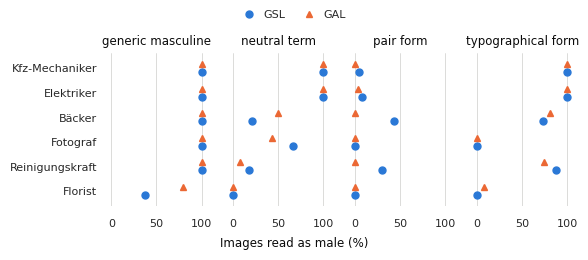

In [3]:
shares = load_shares()
report(shares)
plot(shares, stacked=False, out_path=OUT_PATH)

## The low-context diagnostic

Without a scene (GSL only), the neutral term is read as male in every image of Kfz-Mechaniker and Elektriker and in none of the other four professions, so the scene is not the only source of the male reading.

In [4]:
LOW_CONTEXT_PATH = Path("figures/low-context.pdf")
SETTINGS = {"test grid": ("o", GSL_COLOUR), "low-context": ("o", "white")}  # marker, face colour


def load_counts() -> pd.DataFrame:
    """Images read as male per profession and gender form, GSL, with and without scene."""
    df = pd.read_csv(READOUT)
    df = df[(df["set"] == "test") & (df["variety"].map(LANGUAGE_FORM) == "GSL")
            & (df["readout_status"] == "single")
            & (df["face_available"].astype(str) == "True")].copy()
    df["setting"] = df["scene_label"].eq("low_context").map({True: "low-context",
                                                             False: "test grid"})
    df["male"] = df["gender"] == "male"
    counts = (df.groupby(["setting", "profession", "condition"])["male"]
              .agg(k="sum", n="size").reset_index())
    counts["share"] = 100 * counts["k"] / counts["n"]
    return counts


def plot_low_context(counts: pd.DataFrame, out_path: Path = LOW_CONTEXT_PATH) -> None:
    # Same page geometry and type sizes as depicted-gender.pdf, so the two read as one pair.
    sns.set_theme(style="whitegrid")
    plt.rcParams.update({
        "font.size": 8, "axes.titlesize": 8.5, "axes.labelsize": 8.5,
        "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    })
    fig, axes = plt.subplots(1, 4, figsize=(5.8, 2.5), sharex=True, sharey=True,
                             layout="constrained")
    rows = {key: i for i, key in enumerate(reversed(list(PROFESSIONS)))}

    for ax, (condition, title) in zip(axes, FORM_LABELS.items()):
        cell = counts[counts["condition"] == condition]
        for setting, (marker, face) in SETTINGS.items():
            sub = cell[cell["setting"] == setting]
            sign = -1 if setting == "test grid" else 1
            ax.plot(sub["share"], [rows[p] + sign * ROW_OFFSET for p in sub["profession"]],
                    marker, color=GSL_COLOUR, markerfacecolor=face, markeredgewidth=1.1,
                    markersize=5, linestyle="none", zorder=3)
        ax.set_title(title, color=INK)
        ax.set_xlim(-10, 110)
        ax.set_xticks([0, 50, 100])
        ax.set_ylim(-0.6, len(rows) - 0.4)
        ax.tick_params(axis="y", length=0)
        ax.xaxis.grid(True, color=GRID, lw=0.5, alpha=0.5)
        ax.yaxis.grid(False)
        sns.despine(ax=ax, left=True, bottom=True)

    axes[0].set_yticks(list(rows.values()), [PROFESSIONS[p] for p in rows])
    handles = [Line2D([], [], marker="o", color=GSL_COLOUR, markerfacecolor=face,
                      markeredgewidth=1.1, markersize=5, linestyle="none")
               for _, face in SETTINGS.values()]
    fig.legend(handles, ["with scene (test grid)", "without scene (low-context diagnostic)"],
               loc="outside upper center", ncol=2, frameon=False, handlelength=1.0,
               columnspacing=1.6)
    fig.supxlabel("Images read as male in GSL (%)", fontsize=8.5, color=INK)
    fig.get_layout_engine().set(w_pad=0.06, h_pad=0.04, wspace=0.08)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(out_path, bbox_inches="tight")
    print(f"-> {out_path}")


def report_low_context(counts: pd.DataFrame) -> None:
    """Every low-context cell as k of n, and the totals per gender form."""
    low = counts[counts["setting"] == "low-context"]
    table = (low.assign(cell=low["k"].astype(str) + "/" + low["n"].astype(str))
             .pivot(index="profession", columns="condition", values="cell")
             .reindex(index=list(PROFESSIONS), columns=list(FORM_LABELS)))
    print("Low-context diagnostic, images read as male (k/n):")
    display(table)
    totals = low.groupby("condition")[["k", "n"]].sum().reindex(list(FORM_LABELS))
    print("\nTotals per gender form:")
    display(totals)
    print(f"\nImages per low-context cell: {low['n'].min()} to {low['n'].max()}")

Low-context diagnostic, images read as male (k/n):


condition,generic_masc,neutral_term,pair_form,typographical
profession,,,,
mechaniker,4/4,5/5,0/5,5/5
elektriker,5/5,4/4,0/4,4/4
baecker,5/5,0/3,2/5,3/5
fotograf,5/5,0/5,0/5,0/5
reinigungskraft,3/3,0/5,1/4,3/3
florist,1/5,0/4,0/5,0/5



Totals per gender form:


,k,n
condition,,
generic_masc,23,27
neutral_term,9,26
pair_form,3,28
typographical,15,27



Images per low-context cell: 3 to 5


-> figures/low-context.pdf


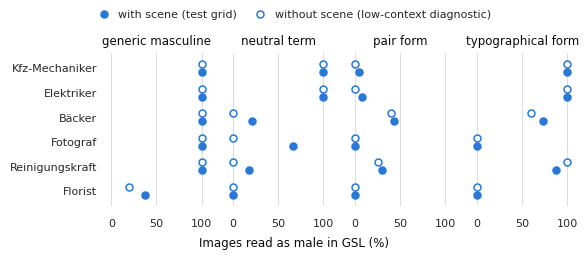

In [5]:
counts = load_counts()
report_low_context(counts)
plot_low_context(counts, out_path=LOW_CONTEXT_PATH)

## Conjunct order of the pair form

With the masculine conjunct first, the reading changes from female to male in 22 of 90 comparable pairs, all of them Kfz-Mechaniker; no Florist pair changes.

In [6]:
def readout(path: Path) -> dict[str, dict]:
    if not path.exists():
        raise SystemExit(f"missing {path}; run classify_depicted_gender.py over its manifest first")
    return pd.read_csv(path, dtype=str, keep_default_na=False).set_index("image_id", drop=False).to_dict("index")

In [7]:
SWAP_DIR = Path("data/order_swap")
MAIN_RUN = Path("data/main_run")
OUT = Path("exports/order_swap_comparison.csv")

In [8]:
swapped = readout(SWAP_DIR / "mivolo_results.csv")
reference = readout(MAIN_RUN / "mivolo_results.csv")

rows = []
for mf in swapped.values():
    ff = reference.get(mf["female_first_image_id"])
    if ff is None:
        raise SystemExit(f"no main-run readout for {mf['female_first_image_id']}")
    comparable = all(r["readout_status"] == "single" and str(r["face_available"]) == "True"
                     for r in (ff, mf))
    rows.append({
        "profession": mf["profession"], "scene_label": mf["scene_label"],
        "variety": mf["variety"], "seed": mf["seed"],
        "ff_status": ff["readout_status"], "ff_gender": ff["gender"],
        "ff_face": ff["face_available"], "ff_n_people": ff["n_people"],
        "mf_status": mf["readout_status"], "mf_gender": mf["gender"],
        "mf_face": mf["face_available"], "mf_n_people": mf["n_people"],
        "changed": (ff["gender"] != mf["gender"]) if comparable else "",
    })
rows.sort(key=lambda r: (r["profession"], r["variety"], r["scene_label"], int(r["seed"])))

OUT.parent.mkdir(parents=True, exist_ok=True)
pd.DataFrame(rows).to_csv(OUT, index=False, lineterminator="\r\n")

cells: dict[tuple, Counter] = defaultdict(Counter)
for r in rows:
    c = cells[(r["profession"], r["variety"])]
    c["pairs"] += 1
    if r["changed"] == "":
        c["not_comparable"] += 1
        continue
    c["comparable"] += 1
    c[f"{r['ff_gender']}->{r['mf_gender']}"] += 1
display(pd.DataFrame([
    {"profession": prof, "language form": LANGUAGE_FORM[var], "pairs": c["pairs"],
     "comparable": c["comparable"], "female to female": c["female->female"],
     "female to male": c["female->male"], "male to male": c["male->male"],
     "male to female": c["male->female"]}
    for (prof, var), c in sorted(cells.items())]).set_index(["profession", "language form"]))
print(f"\nwritten: {OUT}")

pairs  comparable  female to female  female to male  \
profession language form                                                        
florist    GAL               30          25                25               0   
           GSL               30          20                20               0   
mechaniker GAL               30          21                 8              13   
           GSL               30          24                15               9   

                          male to male  male to female  
profession language form                                
florist    GAL                       0               0  
           GSL                       0               0  
mechaniker GAL                       0               0  
           GSL                       0               0


written: exports/order_swap_comparison.csv
